In [95]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import scipy
import os
import json

## Get the vector field

In [96]:
# direction of the current
def get_angle(u, v):
    return np.arctan(v/(u+1e-8))

def get_magnitude(u, v):
    return np.hypot(u, v)

def get_gradient(u, ax):
    return np.gradient(u, axis = ax)

def get_divergence(u, v):
    return get_gradient(u, 0) + get_gradient(v, 1)

def get_curl(u, v):
    return get_gradient(v, 0) - get_gradient(u, 1)

In [97]:
step = 1
angles, divs, mags, curls, uarr, varr = [],[],[],[],[],[]
for i in range(1,len(os.listdir("./vectors/vectors"))+1,step):
    data = np.load(f"vectors/vectors/frame_{i:05}.npz")
    
    u = data["u"]
    v = data["v"]

    # u = cv2.resize(u, None, fx = 0.5, fy = 0.5, interpolation=cv2.INTER_LINEAR)
    # v = cv2.resize(v, None, fx = 0.5, fy = 0.5, interpolation=cv2.INTER_LINEAR)
    
    # Y, X = np.mgrid[
    #     0:u.shape[0]:step,
    #     0:u.shape[1]:step
    # ]
    # angle_map = get_angle(u,v)
    # divergence_map = get_divergence(u,v)
    # magnitude_map = get_magnitude(u, v)
    # curl_map = get_curl(u,v)

    # angles.append(angle_map)
    # divs.append(divergence_map)
    # mags.append(magnitude_map)
    # curls.append(curl_map)
    uarr.append(u)
    varr.append(v)

# plt.figure(figsize=(12, 8))

# plt.quiver(
#     X,
#     Y,
#     u[::step, ::step],
#     # You might notice the minus sign, this is because for image coordinates, there is an increasing Y downwards but for matplotlib, it assumes Y increases upwards, small issue to take note of
#     -v[::step, ::step]
# )

# plt.gca().invert_yaxis()
# plt.show()

In [41]:
# def get_characteristic_frequencies(field_3d, dt, top_k=5):
#     """Applies a 3D window and rfftn, returning top temporal frequencies."""
#     Nt, Ny, Nx = field_3d.shape[0], field_3d.shape[1], field_3d.shape[2]
    
#     # Apply a 3D Hann window to suppress spectral leakage from video boundaries
#     win_t = np.hanning(Nt)[:, None, None]
#     win_y = np.hanning(Ny)[None, :, None]
#     win_x = np.hanning(Nx)[None, None, :]
#     windowed_field = field_3d * (win_t * win_y * win_x)
    
#     # Compute 3D Real FFT across (time, y, x)
#     spectrum = np.abs(scipy.fft.rfftn(windowed_field, workers=-1))
    
#     # Marginalize (sum energy) over spatial frequencies (ky, kx) to get temporal profile
#     temporal_energy = np.sum(spectrum, axis=(1, 2))
#     freqs = scipy.fft.rfftfreq(Nt, d=dt)
    
#     # Ignore 0 Hz (DC offset / static background flow)
#     temporal_energy[0] = 0
    
#     # Find the top K dominant frequencies
#     top_indices = np.argsort(temporal_energy)[::-1][:top_k]
#     return freqs[top_indices], temporal_energy[top_indices]

# fps = 1/30
# dt = fps * step
# div_freqs, div_amps = get_characteristic_frequencies(np.array(divs), dt)
# curl_freqs, curl_amps = get_characteristic_frequencies(np.array(curls), dt)
# mag_freqs, mag_amps = get_characteristic_frequencies(np.array(mags), dt)

IndexError: index 102 is out of bounds for axis 0 with size 52

In [8]:
# 3. Musical Scale Mapping (C Major Pentatonic across 3 octaves: C3 to A5)
# Frequencies in Hz
PENTATONIC_HZ = np.array([
    130.81, 146.83, 164.81, 196.00, 220.00,  # Octave 3 (Bass / Divergence)
    261.63, 293.66, 329.63, 392.00, 440.00,  # Octave 4 (Mid / Curl)
    523.25, 587.33, 659.25, 783.99, 880.00   # Octave 5 (High)
])

def freq_to_musical_hz(raw_freq, max_nyquist=15.0, octave_offset=0):
    """Maps a 0–15 Hz ocean oscillation frequency to a pleasant musical note."""
    # Normalize log-scaled frequency to [0, 1]
    norm = np.clip(np.log1p(raw_freq) / np.log1p(max_nyquist), 0, 0.999)
    idx = int(norm * 5) + (octave_offset * 5)
    return float(PENTATONIC_HZ[np.clip(idx, 0, len(PENTATONIC_HZ) - 1)])


In [98]:
#low memory code
win_t = 60          # 2.0-second temporal window - chunksize
hop_t = 15          # Update musical grid every 0.5 seconds
patch_xy = 16       # 16x16 spatial neighborhood per grid cell
fps = 30.0
dt = 1.0 / fps

def load_frame(i):
    """Load frame i (0-based) -> (u, v)."""
    data = np.load(f"vectors/vectors/frame_{i+1:05}.npz")
    return data["u"], data["v"]

num_files = len(os.listdir("./vectors/vectors"))
time_steps = range(0, num_files - win_t + 1, hop_t)   # every full window that fits

u0, _ = load_frame(0)
ys, xs = u0.shape

freqs = scipy.fft.rfftfreq(win_t, d=dt)

grid_y = ys // patch_xy
grid_x = xs // patch_xy

hanning_3d = (np.hanning(win_t)[:, None, None] * np.hanning(patch_xy)[None, :, None] * np.hanning(patch_xy)[None, None, :])

# Output array: [time_step, grid_y, grid_x, spec]
c_sonification_grid = np.zeros((len(time_steps), grid_y, grid_x, len(freqs)), dtype=np.float32)
d_sonification_grid = np.zeros((len(time_steps), grid_y, grid_x, len(freqs)), dtype=np.float32)
m_sonification_grid = np.zeros((len(time_steps), grid_y, grid_x), dtype=np.float32)

# Sliding window of frames [t_start, t_start + win_t). Created once, before the loop,
# so each step keeps the previous window and only loads the hop_t new frames.
uarr = varr = None

for t_idx, t_start in enumerate(time_steps):
    print(t_start)
    if uarr is None:
        # first window: load all win_t frames
        frames = [load_frame(t_start + j) for j in range(win_t)]
        uarr = np.array([f[0] for f in frames])
        varr = np.array([f[1] for f in frames])
    else:
        # drop the oldest hop_t frames, append the hop_t frames at the END of the new window
        new = [load_frame(t_start + win_t - hop_t + j) for j in range(hop_t)]
        uarr = np.concatenate([uarr[hop_t:], np.array([f[0] for f in new])], axis=0)
        varr = np.concatenate([varr[hop_t:], np.array([f[1] for f in new])], axis=0)
    assert uarr.shape[0] == win_t

    du_dy, du_dx = np.gradient(uarr, axis=(1, 2))
    dv_dy, dv_dx = np.gradient(varr, axis=(1, 2))

    divergence = du_dx + dv_dy
    curl = dv_dx - du_dy
    magnitude = np.hypot(uarr, varr)

    for gy in range(grid_y):
        for gx in range(grid_x):
            y0, y1 = gy * patch_xy, (gy + 1) * patch_xy
            x0, x1 = gx * patch_xy, (gx + 1) * patch_xy

            # Extract local 3D cubes
            c_cube = curl[:, y0:y1, x0:x1] * hanning_3d
            d_cube = divergence[:, y0:y1, x0:x1] * hanning_3d
            m_cube = magnitude[:, y0:y1, x0:x1]

            # FFT along time, summed over the patch -> one temporal spectrum per cell
            c_spec = np.sum(np.abs(scipy.fft.rfftn(c_cube, axes=0)), axis=(1, 2))
            d_spec = np.sum(np.abs(scipy.fft.rfftn(d_cube, axes=0)), axis=(1, 2))

            c_sonification_grid[t_idx, gy, gx, :] = c_spec
            d_sonification_grid[t_idx, gy, gx, :] = d_spec
            m_sonification_grid[t_idx, gy, gx] = float(np.mean(m_cube))

# No normalization here: export_soundscape.py scales every feature to 0..1.

0
15
30
45
60
75
90
105
120
135
150
165
180
195
210
225
240
255
270
285
300
315
330
345
360
375
390
405
420
435
450
465
480
495
510
525
540
555
570
585
600
615
630
645
660
675
690
705
720
735
750
765
780
795
810
825
840
855
870
885
900
915
930
945
960
975
990
1005
1020
1035
1050
1065
1080
1095
1110
1125
1140
1155
1170
1185
1200
1215
1230
1245
1260
1275
1290
1305
1320
1335
1350
1365
1380
1395
1410
1425
1440
1455
1470
1485
1500
1515
1530
1545
1560
1575
1590
1605
1620
1635
1650
1665
1680
1695
1710
1725
1740
1755
1770
1785
1800
1815
1830
1845
1860
1875
1890
1905
1920
1935
1950
1965
1980
1995


[2.3734863 1.9302313 1.1952419 1.1793957 1.4222745 1.3458633 1.7043425
 1.9327176 1.4636363 1.325134  1.6810133 2.1750288 2.070797  1.6139218
 1.3433357 1.513437  1.426941  1.919223  1.2210776 2.1257467 1.6016543
 1.7150065 1.1497844 1.9039376 1.7398468 1.1096499 1.6363534 1.4163839
 1.5299357 1.7818155 1.7469338]


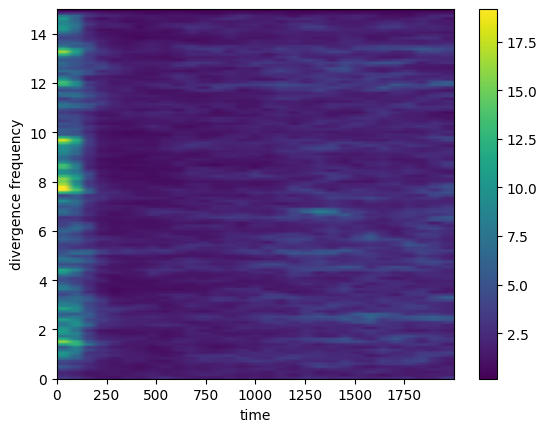

In [99]:
#plt.pcolormesh(times, freqs, c_spec)
print(d_sonification_grid[1,40,2])
plt.imshow(d_sonification_grid[:,40,2], aspect='auto', origin='lower', extent=[0, Nt-win_t, freqs[0], freqs[-1]])
plt.xlabel('time')
plt.ylabel('divergence frequency')
plt.colorbar()
plt.show()



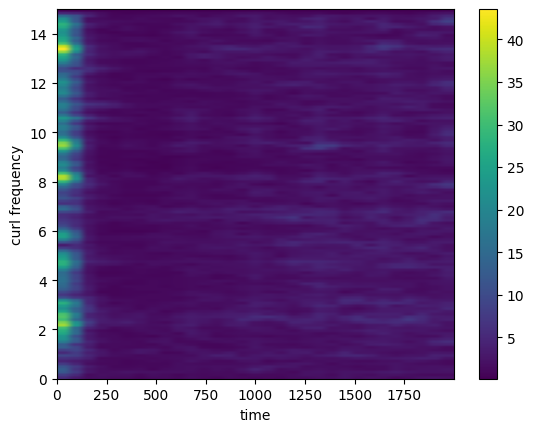

In [100]:
plt.imshow(c_sonification_grid[:,40,2], aspect='auto', origin='lower', extent=[0, Nt-win_t, freqs[0], freqs[-1]])
plt.xlabel('time')
plt.ylabel('curl frequency')
plt.colorbar()
plt.show()


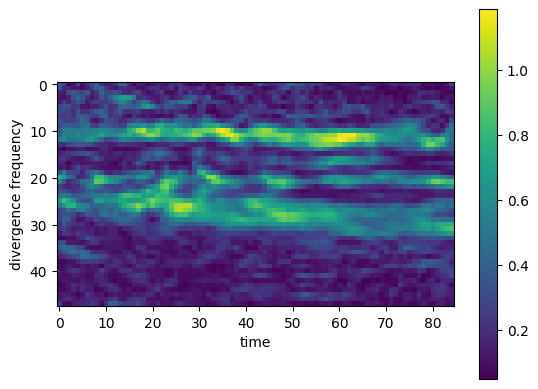

In [101]:
#print(m_sonification_grid[:,40,2])
plt.imshow(m_sonification_grid[8,:,:])
plt.xlabel('time')
plt.ylabel('divergence frequency')
plt.colorbar()
plt.show()


In [90]:
# vector magnitude linked to amplitude of sound
# if curl is high, we play more gurgling water
# if divergence is high, we play more flowing water
from pydub import AudioSegment

bgm = AudioSegment.from_file("music/sfxmint-underwater-ambience-02.mp3")

high_freq_curl = AudioSegment.from_file("music/high_curl.mp3")
low_freq_curl = AudioSegment.from_file("music/low_curl.mp3")

high_freq_div = AudioSegment.from_file("music/high_divergence.mp3")
low_freq_div = AudioSegment.from_file("music/low_divergence.mp3")

high_magnitude = AudioSegment.from_file("music/high_magnitude.mp3")
#low_magnitude = AudioSegment.from_file(".mp3")

mixed = high_magnitude.overlay(high_freq_curl, position=0)
mixed

In [102]:
np.savez('output/curl_grid.npz', c_sonification_grid)
np.savez('output/div_grid.npz', d_sonification_grid)
np.savez('output/mag_grid.npz', m_sonification_grid)


In [86]:
#def map_frequency_to_audio():
#
PENTATONIC_HZ = np.array([
    130.81, 146.83, 164.81, 196.00, 220.00,  # Octave 3 (Bass / Divergence)
    261.63, 293.66, 329.63, 392.00, 440.00,  # Octave 4 (Mid / Curl)
    523.25, 587.33, 659.25, 783.99, 880.00   # Octave 5 (High)
])

def freq_to_musical_hz(raw_freq, max_nyquist=15.0, octave_offset=0):
    """Maps a 0–15 Hz ocean oscillation frequency to a pleasant musical note."""
    # Normalize log-scaled frequency to [0, 1]
    norm = np.clip(np.log1p(raw_freq) / np.log1p(max_nyquist), 0, 0.999)
    idx = int(norm * 5) + (octave_offset * 5)
    return float(PENTATONIC_HZ[np.clip(idx, 0, len(PENTATONIC_HZ) - 1)])


array([[[[ 8.555976  ,  6.0575266 ,  2.6411006 , ...,  2.6250124 ,
           1.9614644 ,  1.6722206 ],
         [ 8.4322195 ,  6.74561   ,  5.3727317 , ...,  2.0284214 ,
           1.4824886 ,  1.2114924 ],
         [ 8.291364  ,  8.482303  ,  6.440609  , ...,  1.3848878 ,
           2.0892687 ,  1.0891774 ],
         ...,
         [ 6.5080314 ,  4.6167097 ,  3.9129562 , ...,  1.149615  ,
           0.9855491 ,  1.4104601 ],
         [11.948493  ,  7.8391476 ,  3.1510255 , ...,  2.1115172 ,
           1.6947379 ,  1.2375845 ],
         [ 5.217918  ,  6.0629134 ,  3.976254  , ...,  1.5792885 ,
           1.5193474 ,  1.3204443 ]],

        [[ 7.260441  ,  5.704727  ,  3.0772252 , ...,  0.89654785,
           1.4701147 ,  2.0132368 ],
         [ 8.775647  ,  7.3751426 ,  4.286604  , ...,  1.5766575 ,
           1.4589533 ,  2.4039495 ],
         [22.430138  , 15.75952   ,  8.743889  , ...,  2.238054  ,
           1.8286284 ,  2.486811  ],
         ...,
         [14.430156  , 10.941681  

In [52]:
# Normalize volume to [0.0, 1.0]
max_mag = np.max(sonification_grid[..., 2])
if max_mag > 0:
    sonification_grid[..., 2] /= max_mag

# Export lightweight JSON for the browser player
with open("ocean_sonification_2.json", "w") as f:
    json.dump({
        "hop_seconds": hop_t / fps,
        "grid_y": grid_y,
        "grid_x": grid_x,
        "data": np.round(sonification_grid, 2).tolist()
    }, f)

print("Saved ocean_sonification.json successfully.")


Saved ocean_sonification.json successfully.


In [ ]:
dom_curl_freq = freqs[np.argmax(c_spec)]
dom_div_freq = freqs[np.argmax(d_spec)]
sonification_grid[t_idx, gy, gx, 0] = freq_to_musical_hz(dom_curl_freq, octave_offset=1)
sonification_grid[t_idx, gy, gx, 1] = freq_to_musical_hz(dom_div_freq, octave_offset=0)
sonification_grid[t_idx, gy, gx, 2] = float(np.mean(m_cube))


In [44]:
scipy.fft.rfftn(c_cube, axes=0)

array([[[ 0.00000000e+00+0.00000000e+00j,
          0.00000000e+00+0.00000000e+00j,
          0.00000000e+00+0.00000000e+00j, ...,
          0.00000000e+00+0.00000000e+00j,
          0.00000000e+00+0.00000000e+00j,
          0.00000000e+00+0.00000000e+00j],
        [ 0.00000000e+00+0.00000000e+00j,
          1.71730427e-03+0.00000000e+00j,
          6.42272238e-03+0.00000000e+00j, ...,
         -1.23515776e-04+0.00000000e+00j,
         -7.99439497e-05+0.00000000e+00j,
          0.00000000e+00+0.00000000e+00j],
        [ 0.00000000e+00+0.00000000e+00j,
          8.96269569e-03+0.00000000e+00j,
          3.21416245e-02+0.00000000e+00j, ...,
          5.20381422e-03+0.00000000e+00j,
          1.18607210e-03+0.00000000e+00j,
          0.00000000e+00+0.00000000e+00j],
        ...,
        [ 0.00000000e+00+0.00000000e+00j,
          8.04466880e-03+0.00000000e+00j,
          3.21076101e-02+0.00000000e+00j, ...,
          1.72613245e-02+0.00000000e+00j,
          4.54490592e-03+0.00000000e+00j

In [5]:
# # 1. Load your precomputed ocean current arrays: shape (2040, Ny, Nx)
# # Replace these dummy arrays with np.load('u.npy') and np.load('v.npy')
# uarr = np.array(uarr)
# varr = np.array(varr)
# Nt, Ny, Nx = uarr.shape[0], uarr.shape[1], uarr.shape[2]
# fps = 30.0
# dt = 1.0 / fps
# # u = np.random.randn(Nt, Ny, Nx).astype(np.float32)
# # v = np.random.randn(Nt, Ny, Nx).astype(np.float32)

# # 2. Compute Divergence, Curl, and Magnitude
# du_dy, du_dx = np.gradient(uarr, axis=(1, 2))
# dv_dy, dv_dx = np.gradient(varr, axis=(1, 2))

# divergence = du_dx + dv_dy
# curl = dv_dx - du_dy
# magnitude = np.hypot(uarr, varr)


# # 4. Sliding 3D Spatiotemporal FFT over space-time blocks
# win_t = 60          # 2.0-second temporal window
# hop_t = 15          # Update musical grid every 0.5 seconds (136 time steps total)
# patch_xy = 16       # 16x16 spatial neighborhood per grid cell

# time_steps = range(0, Nt - win_t, hop_t)
# grid_y = Ny // patch_xy
# grid_x = Nx // patch_xy

# # Output array: [time_step, grid_y, grid_x, (curl_hz, div_hz, volume)]
# sonification_grid = np.zeros((len(time_steps), grid_y, grid_x, 3), dtype=np.float32)
# freqs = scipy.fft.rfftfreq(win_t, d=dt)
# hanning_3d = (np.hanning(win_t)[:, None, None] * np.hanning(patch_xy)[None, :, None] * np.hanning(patch_xy)[None, None, :])

# for t_idx, t_start in enumerate(time_steps):
#     for gy in range(grid_y):
#         for gx in range(grid_x):
#             y0, y1 = gy * patch_xy, (gy + 1) * patch_xy
#             x0, x1 = gx * patch_xy, (gx + 1) * patch_xy
            
#             # Extract local 3D cubes
#             c_cube = curl[t_start:t_start+win_t, y0:y1, x0:x1] * hanning_3d
#             d_cube = divergence[t_start:t_start+win_t, y0:y1, x0:x1] * hanning_3d
#             m_cube = magnitude[t_start:t_start+win_t, y0:y1, x0:x1]
            
#             # 3D FFT -> sum spatial wavenumbers to get dominant temporal oscillation
#             c_spec = np.sum(np.abs(scipy.fft.rfftn(c_cube)), axis=(1, 2))
#             d_spec = np.sum(np.abs(scipy.fft.rfftn(d_cube)), axis=(1, 2))
#             # c_spec = d_spec = 0  # Ignore 0 Hz static offset
            
#             dom_curl_freq = freqs[np.argmax(c_spec)]
#             dom_div_freq = freqs[np.argmax(d_spec)]
            
#             # Map Curl -> Mid-range note, Divergence -> Bass note, Magnitude -> Volume
#             sonification_grid[t_idx, gy, gx, 0] = freq_to_musical_hz(dom_curl_freq, octave_offset=1)
#             sonification_grid[t_idx, gy, gx, 1] = freq_to_musical_hz(dom_div_freq, octave_offset=0)
#             sonification_grid[t_idx, gy, gx, 2] = float(np.mean(m_cube))

# # Normalize volume to [0.0, 1.0]
# max_mag = np.max(sonification_grid[..., 2])
# if max_mag > 0:
#     sonification_grid[..., 2] /= max_mag

# # Export lightweight JSON for the browser player
# with open("ocean_sonification.json", "w") as f:
#     json.dump({
#         "hop_seconds": hop_t / fps,
#         "grid_y": grid_y,
#         "grid_x": grid_x,
#         "data": np.round(sonification_grid, 2).tolist()
#     }, f)

# print("Saved ocean_sonification.json successfully.")


Saved ocean_sonification.json successfully.


In [21]:
# np.sum(np.abs(scipy.fft.rfftn(c_cube)), axis=(1,2))

array([10.79591903,  5.9957863 ,  1.73567835,  1.68281392,  2.33646784,
        1.07086254,  2.25092877,  1.71479376,  1.71219816,  2.07498814,
        1.03669659,  2.30277551,  1.73467599,  1.6638996 ,  2.1747021 ,
        1.23911779,  2.34777711,  1.62877709,  1.67610813,  2.16379053,
        1.05531213,  2.21868208,  1.67323023,  1.67687743,  2.15476796,
        1.09199819,  2.31616597,  1.72379507,  1.68327473,  2.07351841,
        1.1583293 ,  2.27831824,  1.6482392 ,  1.66950282,  2.20831778,
        1.14330259,  2.28287688,  1.65075784,  1.68925148,  2.09809252,
        0.99722641,  2.22744142,  1.75498655,  1.69636117,  2.09234833,
        1.23788872,  2.3954711 ,  1.63935082,  1.65132921,  2.17622661,
        1.13813088,  2.1742377 ,  1.65230413,  1.72069474,  2.11168781,
        1.03846835,  2.33419722,  1.81680396,  1.71203297,  5.43268783])